# 강판 결함 유형 분류 — 문제 정의 · EDA · 평가 기준 · 전처리
**문제 정의 · 데이터 이해 및 탐색(EDA) · 평가 기준 설정 · 데이터 품질 확인 및 전처리**

| 항목 | 내용 |
|---|---|
| 데이터 | Steel Plates Faults (UCI ML Repository) — `data/raw/Faults.csv` |
| 공통 기준 | Train/Test 80:20 Stratified, `random_state=42`, StratifiedKFold 5-fold, 핵심 지표 Macro F1 |
| 산출물 | `results/eda/Taegyeom_eda_*.csv`, `figures/Taegyeom_eda_*.png` (전처리 데이터 `data/processed/Faults_processed.csv`는 팀 공통 파일과 동일함을 검증) |

> **EDA 범위 원칙**: 데이터 구조·품질·전체 클래스 분포는 전체 데이터(1,941건)로 확인하고,
> **Feature–Target 관계 분석과 전처리 판단에 쓰는 통계는 Train(1,552건)만 사용**합니다.
> Test 데이터의 정보가 모델링 의사결정에 섞이지 않도록 하기 위함입니다.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import kruskal
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE_DIR / "src"))

from config import RANDOM_STATE, TEST_SIZE, TARGET_COLS
from Taegyeom_model_utils import (TARGET_NAME, CLASS_ORDER, DROPPED_FEATURES, DISCRETE_FEATURES, LABEL_RENAME,
                                  SCORING_EXTENDED, validate_raw, make_processed, build_preprocessor)

FIG_DIR = BASE_DIR / "figures";            FIG_DIR.mkdir(parents=True, exist_ok=True)
EDA_DIR = BASE_DIR / "results" / "eda";     EDA_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

# ---- 시각화 공통 스타일 (단일 색상 + 중립 회색, 한글 폰트) ----
BLUE, BLUE_LIGHT, RED, GRAY_MID = "#2a78d6", "#86b6ef", "#e34948", "#f0efec"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [BLUE, GRAY_MID, RED])
def save(fig, name): fig.savefig(FIG_DIR / name); plt.show()

---
# 1. 문제 정의

### 1-1. 예측하려는 Target
- 이미 **발견된 강판 결함 1건**의 위치·크기·형상·밝기·강종·두께 측정값으로 **7가지 결함 유형 중 하나**를 예측합니다.
- 원본의 one-hot 정답 열 7개 중 값이 1인 열 이름을 단일 라벨 `target`으로 만듭니다.
  모든 행이 정확히 1개의 정답을 가지므로(검증: 2-2) **다중 라벨이 아닌 7-class 다중 분류(Multiclass Classification)** 입니다.
- 데이터에 **정상 제품이 없으므로** 정상/불량 판별이나 결함 발생 전 고장 예측 문제가 **아닙니다**.

### 1-2. 각 Class의 의미
원 데이터(Buscema et al., Semeion)는 유형별 상세 정의를 제공하지 않으므로, 이름과 측정값 특성(2번 EDA에서 확인)을 바탕으로 정리했습니다.

| Class | 일반적 의미 | 데이터에서 보이는 특징 (Train 중앙값 기준, 2-5) | 건수(비율) |
|---|---|---|---|
| **Other_Faults** | 6개 유형으로 분류되지 않은 기타 결함 (이질적 집합) | 뚜렷한 고유 패턴 없음, 여러 유형과 값 범위 겹침 | 673 (34.67%) |
| **Bumps** | 표면 돌출·요철 | A300 강종 비중 높음, 소형, 가장자리 지표 중간 | 402 (20.71%) |
| **K_Scratch** | K형(폭 방향) 긁힘 | **면적·둘레가 압도적으로 큼**, X 위치가 강판 가장자리(X_Minimum 중앙값 41), 거의 전부 A400·두께 40 | 391 (20.14%) |
| **Z_Scratch** | Z형(길이 방향) 긁힘 | 대부분 A300, X 위치가 가장자리 쪽 | 190 (9.79%) |
| **Pastry** | 패치 형태의 표면 결함 | Orientation_Index 양수(세로로 긴 형상), Outside_Global_Index=1 | 158 (8.14%) |
| **Stains** | 얼룩 | **매우 작은 면적**(중앙값 16px), 밝기가 높음, 거의 전부 A400 | 72 (3.71%) |
| **Dirtiness** | 오염(이물) | 두께가 두꺼운 편(중앙값 100), Square_Index 낮음(길쭉한 형상) | 55 (2.83%) |

### 1-3. 모델 예측 결과의 활용
- 검사 단계에서 결함이 검출되면 모델이 **결함 유형 후보(및 클래스별 확률)를 제시**하고, 검사 담당자가 이를 검토·확정합니다.
- 유형이 정해지면 **원인 공정 추적**(예: 긁힘 → 롤·이송 설비, 오염 → 세정·환경)과 **후속 조치**(재작업, 등급 하향, 폐기)를 빠르게 결정할 수 있습니다.
- 완전 자동 판정이 아니라 **검사자 보조(Decision Support)** 용도로 가정합니다.

### 1-4. 오분류 시 발생하는 문제
| 오분류 유형 | 현장 영향 |
|---|---|
| **소수 유형(Dirtiness·Stains·Pastry) → Other_Faults / Bumps** | 가장 흔하고 위험한 오류. 소수 유형이 "기타"로 흡수되면 **특정 원인 공정의 이상 신호가 묻혀** 원인 추적·조치가 늦어짐 |
| **Other_Faults → 특정 유형** (오경보) | 잘못된 공정을 점검하게 되어 **불필요한 점검 비용·라인 정지** 발생 |
| **K_Scratch ↔ Z_Scratch** (긁힘끼리 혼동) | 긁힘 방향에 따라 의심 설비가 달라 원인 추적 방향이 틀어짐 |
| **Bumps ↔ Other_Faults** | 다수 클래스 간 혼동으로 건수가 많아 전체 운영 효율에 영향 |

### 1-5. 더 중요하게 고려할 오류
- **소수 유형을 놓치는 오류(소수 클래스의 Recall 저하)** 를 가장 중요하게 봅니다. 다수 유형만 잘 맞혀도 Accuracy는 높게 나오기 때문에,
  Accuracy만으로는 이 오류가 드러나지 않습니다.
- 다만 **오경보(Precision 저하)도 비용**이므로, 소수 클래스 Recall만 높이는 것이 아니라 **Precision과 Recall의 균형(F1)을 클래스별로** 봅니다.

> **문제 정의 요약**: *강판 결함의 측정 특성으로 7가지 결함 유형을 분류하여 검사자의 유형 판정을 보조하고,
> 특히 Dirtiness·Stains·Pastry 같은 소수 유형이 다수 유형(Other_Faults·Bumps)으로 흡수되어 놓치는 오류를 줄이는 것을 중요하게 고려한다.*

---
# 2. 데이터 이해 및 탐색
## 2-1. 데이터 크기와 Feature

In [2]:
raw = pd.read_csv(BASE_DIR / "data" / "raw" / "Faults.csv")
FEATURES_RAW = [c for c in raw.columns if c not in TARGET_COLS]
print(f"원본 크기: {raw.shape[0]:,}행 × {raw.shape[1]}열  (입력 {len(FEATURES_RAW)}개 + 정답 표시 열 {len(TARGET_COLS)}개)")
print("dtype 분포:", raw[FEATURES_RAW].dtypes.value_counts().to_dict())
raw.head()

원본 크기: 1,941행 × 34열  (입력 27개 + 정답 표시 열 7개)
dtype 분포: {dtype('int64'): 14, dtype('float64'): 13}


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [3]:
groups = {
    "위치": ["X_Minimum", "X_Maximum", "Y_Minimum", "Y_Maximum"],
    "크기·둘레": ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "LogOfAreas", "Log_X_Index", "Log_Y_Index", "SigmoidOfAreas"],
    "밝기": ["Sum_of_Luminosity", "Minimum_of_Luminosity", "Maximum_of_Luminosity", "Luminosity_Index"],
    "형상·가장자리 지표": ["Edges_Index", "Empty_Index", "Square_Index", "Outside_X_Index", "Edges_X_Index",
                     "Edges_Y_Index", "Outside_Global_Index", "Orientation_Index"],
    "공정·강판 정보": ["Length_of_Conveyer", "TypeOfSteel_A300", "TypeOfSteel_A400", "Steel_Plate_Thickness"],
}
info = []
for g, cols in groups.items():
    for c in cols:
        s = raw[c]
        kind = "이진(범주)" if s.nunique() == 2 else ("이산(3값)" if s.nunique() <= 3 else "연속형")
        info.append([g, c, str(s.dtype), kind, s.nunique(), s.min(), s.max()])
feat_info = pd.DataFrame(info, columns=["그룹", "변수", "dtype", "유형", "고유값 수", "최소", "최대"])
assert len(feat_info) == 27
feat_info.to_csv(EDA_DIR / "Taegyeom_eda_feature_info.csv", index=False)
feat_info

,그룹,변수,dtype,유형,고유값 수,최소,최대
0,위치,X_Minimum,int64,연속형,962,0.0000,1.705000e+03
1,위치,X_Maximum,int64,연속형,994,4.0000,1.713000e+03
2,위치,Y_Minimum,int64,연속형,1939,6712.0000,1.298766e+07
3,위치,Y_Maximum,int64,연속형,1940,6724.0000,1.298769e+07
4,크기·둘레,Pixels_Areas,int64,연속형,920,2.0000,1.526550e+05
5,크기·둘레,X_Perimeter,int64,연속형,399,2.0000,1.044900e+04
6,크기·둘레,Y_Perimeter,int64,연속형,317,1.0000,1.815200e+04
7,크기·둘레,LogOfAreas,float64,연속형,914,0.3010,5.183700e+00
8,크기·둘레,Log_X_Index,float64,연속형,183,0.3010,3.074100e+00
9,크기·둘레,Log_Y_Index,float64,연속형,217,0.0000,4.258700e+00


**확인 결과**
- 27개 입력 변수는 모두 숫자형(int64 14개, float64 13개)이며 문자열 범주형은 없습니다.
- 실질적인 범주형은 **강종 표시 2개(`TypeOfSteel_A300/A400`, 0/1)** 와 0·0.5·1 세 값만 갖는 **`Outside_Global_Index`** 입니다.
- `LogOfAreas`, `Log_X_Index`, `Log_Y_Index`, `SigmoidOfAreas` 는 원본 크기 변수를 변환한 **파생 지표**입니다(4-3에서 수식 관계 확인).
- 행을 식별하는 ID 열은 없습니다.

## 2-2. Target 구조 검증 및 단일 라벨 생성

In [4]:
t = raw[TARGET_COLS]
print("정답 열 값이 모두 0/1 인가:", bool(t.isin([0, 1]).all().all()))
print("행별 정답 합 분포:", t.sum(axis=1).value_counts().to_dict(), "→ 모든 행이 정확히 1개의 정답")

y_all = t.idxmax(axis=1).replace(LABEL_RENAME).rename(TARGET_NAME)   # 원본 열 이름 오타 K_Scatch → K_Scratch
runs = [(grp.iloc[0], len(grp)) for _, grp in y_all.groupby((y_all != y_all.shift()).cumsum())]
print("\n파일 내 행 순서 (같은 클래스가 연속된 구간):", runs)

정답 열 값이 모두 0/1 인가: True
행별 정답 합 분포: {1: 1941} → 모든 행이 정확히 1개의 정답

파일 내 행 순서 (같은 클래스가 연속된 구간): [('Pastry', 158), ('Z_Scratch', 190), ('K_Scratch', 391), ('Stains', 72), ('Dirtiness', 55), ('Bumps', 402), ('Other_Faults', 673)]


- 정답 7개 열은 모두 0/1이고 **행 합이 전부 1** → 단일 라벨 변환이 손실 없이 가능합니다.
- 원본 열 이름 `K_Scatch`는 오타이므로 라벨은 **`K_Scratch`** 로 수정합니다(팀 `02_preprocessing.ipynb`와 동일). `TARGET_COLS`는 원본 CSV를 읽기 위해 원래 이름을 유지합니다.
- 원본 파일은 **클래스별로 정렬**되어 있습니다(Pastry → Z_Scratch → … → Other_Faults 순). 순서대로 자르면 분할이 깨지므로
  **반드시 shuffle이 포함된 층화 분할/CV**를 사용해야 합니다(팀 기준 `shuffle=True` 와 일치).

## 2-3. Target의 Class별 데이터 수와 비율

In [5]:
dist = (y_all.value_counts().reindex(CLASS_ORDER).rename("건수").to_frame()
        .assign(비율=lambda d: (d["건수"] / d["건수"].sum() * 100).round(2)))
dist["최대 클래스 대비 배수"] = (dist["건수"].max() / dist["건수"]).round(2)
dist.to_csv(EDA_DIR / "Taegyeom_eda_class_distribution.csv")
print(f"최대/최소 클래스 비 = {dist['건수'].max()} / {dist['건수'].min()} = {dist['건수'].max() / dist['건수'].min():.2f}배")
dist

최대/최소 클래스 비 = 673 / 55 = 12.24배


,건수,비율,최대 클래스 대비 배수
target,,,
Other_Faults,673,34.67,1.00
Bumps,402,20.71,1.67
K_Scratch,391,20.14,1.72
Z_Scratch,190,9.79,3.54
Pastry,158,8.14,4.26
Stains,72,3.71,9.35
Dirtiness,55,2.83,12.24


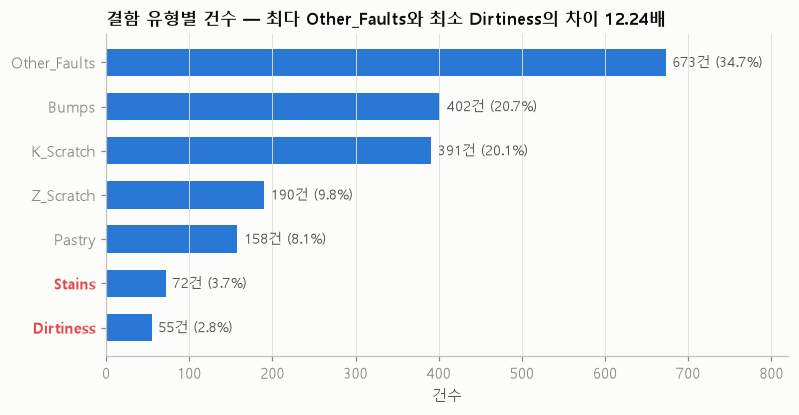

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
d = dist.iloc[::-1]
bars = ax.barh(d.index, d["건수"], color=BLUE, height=0.62)
for b, n, p in zip(bars, d["건수"], d["비율"]):
    ax.text(b.get_width() + 8, b.get_y() + b.get_height() / 2, f"{n:,}건 ({p:.1f}%)", va="center", fontsize=9, color=INK2)
for lbl in ax.get_yticklabels():
    if lbl.get_text() in ("Stains", "Dirtiness"): lbl.set_color(RED); lbl.set_fontweight("bold")
ax.set_xlim(0, 820); ax.grid(axis="y", visible=False); ax.set_xlabel("건수")
ax.set_title("결함 유형별 건수 — 최다 Other_Faults와 최소 Dirtiness의 차이 12.24배")
save(fig, "Taegyeom_eda_class_distribution.png")

**해석**
- 클래스는 **다수(Other_Faults·Bumps·K_Scratch, 합계 75.5%)**, **중간(Z_Scratch·Pastry, 17.9%)**, **희소(Stains·Dirtiness, 6.5%)** 3단계로 나뉩니다.
- 최대/최소 비는 **12.24배**로 "중간 정도"의 불균형입니다. 극단적 불균형(수백 배)은 아니지만,
  희소 2개 클래스는 Test에 각각 **14건·11건**만 남아 클래스별 지표의 불확실성이 큽니다(아래 표).

### Train/Test 층화 분할 결과 (팀 공통 `make_split.py`, index 기반)

In [7]:
train_idx = pd.read_csv(BASE_DIR / "data" / "split" / "train_idx.csv")["index"]
test_idx = pd.read_csv(BASE_DIR / "data" / "split" / "test_idx.csv")["index"]
assert len(set(train_idx) & set(test_idx)) == 0 and len(train_idx) + len(test_idx) == len(raw)

split_tbl = pd.DataFrame({
    "Train 건수": y_all.loc[train_idx].value_counts(), "Test 건수": y_all.loc[test_idx].value_counts(),
}).reindex(CLASS_ORDER)
split_tbl["Train 비율(%)"] = (split_tbl["Train 건수"] / len(train_idx) * 100).round(2)
split_tbl["Test 비율(%)"] = (split_tbl["Test 건수"] / len(test_idx) * 100).round(2)
split_tbl["CV 1-fold 검증 건수(약)"] = (split_tbl["Train 건수"] / 5).round(0).astype(int)
split_tbl["Test 1건 오분류 시 Recall 변동(%p)"] = (100 / split_tbl["Test 건수"]).round(1)
split_tbl.to_csv(EDA_DIR / "Taegyeom_eda_split_distribution.csv")
print(f"Train {len(train_idx)}건 / Test {len(test_idx)}건")
split_tbl

Train 1552건 / Test 389건


,Train 건수,Test 건수,Train 비율(%),Test 비율(%),CV 1-fold 검증 건수(약),Test 1건 오분류 시 Recall 변동(%p)
target,,,,,,
Other_Faults,538,135,34.66,34.70,108,0.7
Bumps,321,81,20.68,20.82,64,1.2
K_Scratch,313,78,20.17,20.05,63,1.3
Z_Scratch,152,38,9.79,9.77,30,2.6
Pastry,126,32,8.12,8.23,25,3.1
Stains,58,14,3.74,3.60,12,7.1
Dirtiness,44,11,2.84,2.83,9,9.1


- 층화 분할로 Train·Test의 클래스 비율이 원본과 거의 같습니다(차이 0.1%p 이내).
- **Dirtiness는 Test 11건 → 1건만 틀려도 Recall이 9.1%p 변동**, CV 각 fold 검증에는 약 9건뿐입니다.
  → 희소 클래스 성능은 **CV 평균 ± 표준편차**로 함께 보고하고, Test 단일 수치를 과대 해석하지 않습니다.

## 2-4. 기초 통계량 및 주요 Feature 분포 (Train 기준)

In [8]:
X_tr = raw.loc[train_idx, FEATURES_RAW]; y_tr = y_all.loc[train_idx]
desc = X_tr.describe().T
desc["skew"] = X_tr.skew()
desc["IQR 이상치 비율(%)"] = (((X_tr < X_tr.quantile(.25) - 1.5 * (X_tr.quantile(.75) - X_tr.quantile(.25))) |
                              (X_tr > X_tr.quantile(.75) + 1.5 * (X_tr.quantile(.75) - X_tr.quantile(.25)))).mean() * 100)
desc = desc.round(3)
desc.to_csv(EDA_DIR / "Taegyeom_eda_describe_train.csv")
desc.sort_values("skew", key=abs, ascending=False)

,count,mean,std,min,25%,50%,75%,max,skew,IQR 이상치 비율(%)
Outside_X_Index,1552.0,0.034,0.060,0.002,0.007,0.010,0.024,8.760000e-01,5.256,19.265
Sum_of_Luminosity,1552.0,206718.642,459112.724,250.000,9548.750,19125.000,83647.250,3.918209e+06,3.246,20.490
Pixels_Areas,1552.0,1870.083,4007.856,2.000,85.000,170.500,822.500,3.733400e+04,3.107,20.425
X_Perimeter,1552.0,107.993,192.130,2.000,15.000,26.500,83.250,1.275000e+03,2.848,18.363
Y_Minimum,1552.0,1662716.644,1811260.019,6712.000,462923.500,1188619.000,2182183.500,1.298766e+07,2.810,4.510
Y_Maximum,1552.0,1662761.350,1811258.419,6724.000,462947.250,1188705.500,2182200.250,1.298769e+07,2.810,4.510
Y_Perimeter,1552.0,74.538,119.202,1.000,13.000,25.000,80.000,9.030000e+02,2.806,9.665
Steel_Plate_Thickness,1552.0,77.881,54.588,40.000,40.000,69.000,80.000,3.000000e+02,2.219,12.307
Maximum_of_Luminosity,1552.0,130.195,18.980,37.000,124.000,127.000,140.000,2.530000e+02,1.223,7.925
Log_X_Index,1552.0,1.337,0.486,0.301,1.000,1.176,1.522,3.074000e+00,0.999,1.933


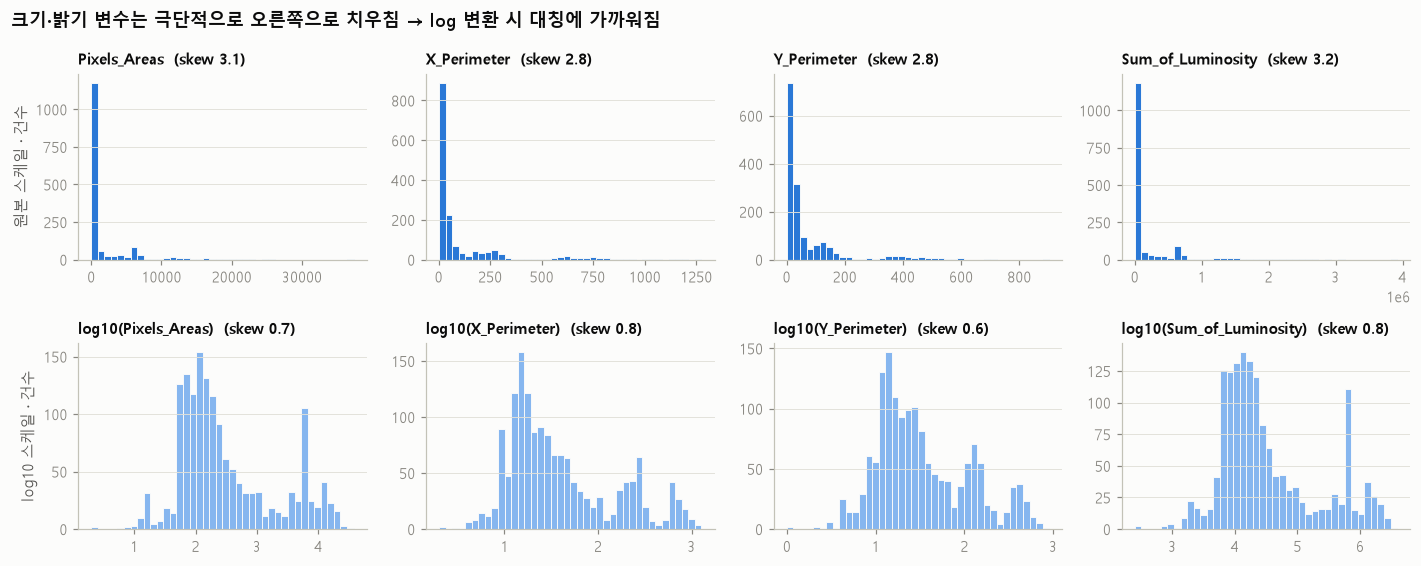

In [9]:
skew_cols = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2))
for i, c in enumerate(skew_cols):
    v = X_tr[c]
    axes[0, i].hist(v, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
    axes[0, i].set_title(f"{c}  (skew {v.skew():.1f})", fontsize=9.5)
    axes[1, i].hist(np.log10(v), bins=40, color=BLUE_LIGHT, edgecolor=SURFACE, linewidth=0.6)
    axes[1, i].set_title(f"log10({c})  (skew {np.log10(v).skew():.1f})", fontsize=9.5)
    for a in axes[:, i]: a.grid(axis="x", visible=False)
axes[0, 0].set_ylabel("원본 스케일 · 건수"); axes[1, 0].set_ylabel("log10 스케일 · 건수")
fig.suptitle("크기·밝기 변수는 극단적으로 오른쪽으로 치우침 → log 변환 시 대칭에 가까워짐", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_eda_skewed_distributions.png")

**해석**
- `Pixels_Areas`, `X/Y_Perimeter`, `Sum_of_Luminosity` 는 Train 기준 왜도 약 2.8~3.2의 **강한 우편향** 분포입니다(`Outside_X_Index`는 5.3). 중앙값은 수십~수만 수준인데 최댓값은 그보다 100배 이상 큽니다.
- 전체 데이터 기준 왜도는 7~40으로 더 큰데, **가장 극단적인 결함 1건(K_Scratch, Pixels_Areas 152,655)이 Test에 포함**되어 있기 때문입니다. 이 행은 10개 변수에서 Train 범위를 벗어나며, Tree 모델은 Train 최댓값 구간으로 처리합니다.
- log10 변환 시 대칭에 가까워지며, 데이터에는 이미 `LogOfAreas`, `Log_X_Index`, `Log_Y_Index` 같은 log 파생 지표가 포함되어 있습니다.
- Tree 계열은 단조 변환에 영향을 받지 않지만, **로지스틱 회귀는 이런 분포에서 계수 추정·수렴이 불안정**할 수 있어 log 변환을 "전처리 변경 실험" 후보로 둡니다.

## 2-5. Feature와 Target의 관계 (Train 기준)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

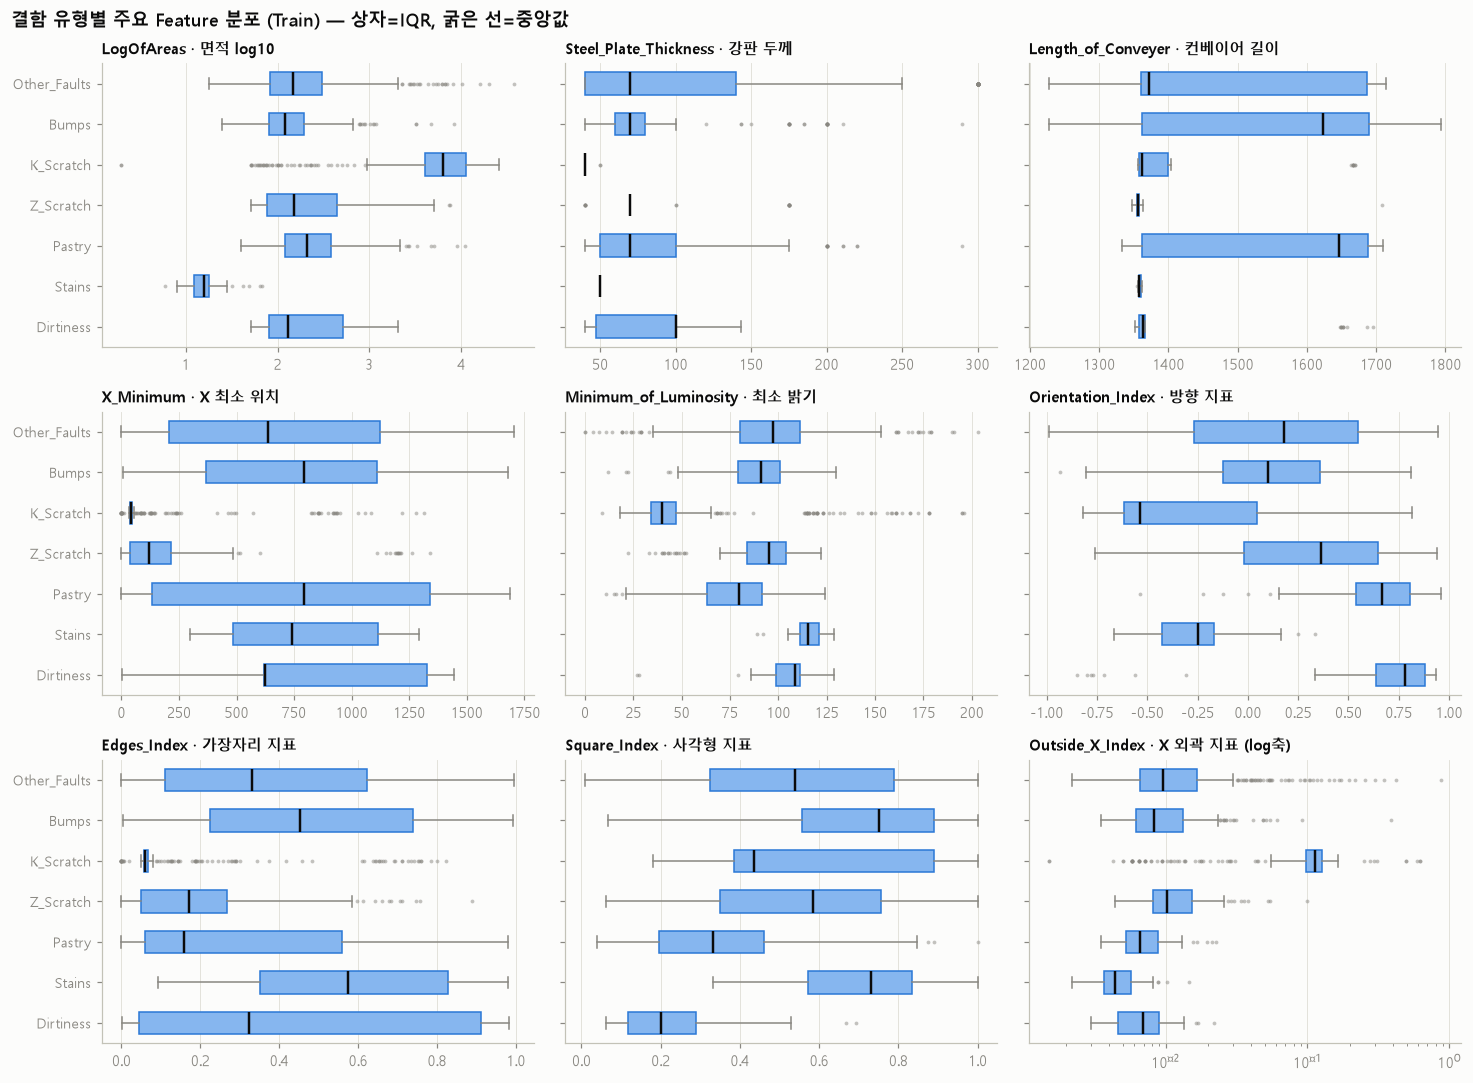

In [10]:
box_cols = [("LogOfAreas", "면적 log10"), ("Steel_Plate_Thickness", "강판 두께"), ("Length_of_Conveyer", "컨베이어 길이"),
            ("X_Minimum", "X 최소 위치"), ("Minimum_of_Luminosity", "최소 밝기"), ("Orientation_Index", "방향 지표"),
            ("Edges_Index", "가장자리 지표"), ("Square_Index", "사각형 지표"), ("Outside_X_Index", "X 외곽 지표 (log축)")]
fig, axes = plt.subplots(3, 3, figsize=(13.5, 10))
for ax, (c, k) in zip(axes.ravel(), box_cols):
    data = [X_tr.loc[y_tr == cl, c] for cl in CLASS_ORDER]
    bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.5),
                    medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for p in bp["boxes"]: p.set(facecolor=BLUE_LIGHT, edgecolor=BLUE, linewidth=1)
    ax.set_yticks(range(1, 8), CLASS_ORDER if ax in axes[:, 0] else [""] * 7, fontsize=9)
    ax.invert_yaxis(); ax.set_title(f"{c} · {k}", fontsize=10); ax.grid(axis="y", visible=False)
    if c == "Outside_X_Index": ax.set_xscale("log")
fig.suptitle("결함 유형별 주요 Feature 분포 (Train) — 상자=IQR, 굵은 선=중앙값", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_eda_feature_by_class_boxplot.png")

In [11]:
med = X_tr.groupby(y_tr).median().reindex(CLASS_ORDER).T.round(3)
med.to_csv(EDA_DIR / "Taegyeom_eda_class_median_train.csv")
med

target,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness
X_Minimum,636.500,794.000,41.000,121.000,794.000,741.500,625.000
X_Maximum,673.000,814.000,212.000,142.500,801.500,747.500,638.000
Y_Minimum,894631.500,1465348.000,1555596.000,1153970.500,1164465.500,1089519.000,2066413.000
Y_Maximum,894645.500,1465360.000,1555663.000,1153988.000,1164511.500,1089523.500,2066535.000
Pixels_Areas,146.000,121.000,6298.000,152.000,210.500,16.000,130.500
X_Perimeter,25.000,17.000,274.000,28.000,20.000,7.000,26.500
Y_Perimeter,22.000,16.000,139.000,23.500,30.500,5.000,29.500
Sum_of_Luminosity,16962.000,12847.000,658162.000,16793.000,21221.000,2072.500,16076.000
Minimum_of_Luminosity,97.000,91.000,40.000,95.000,79.500,115.500,108.500
Maximum_of_Luminosity,127.000,127.000,134.000,124.000,126.000,140.000,133.000


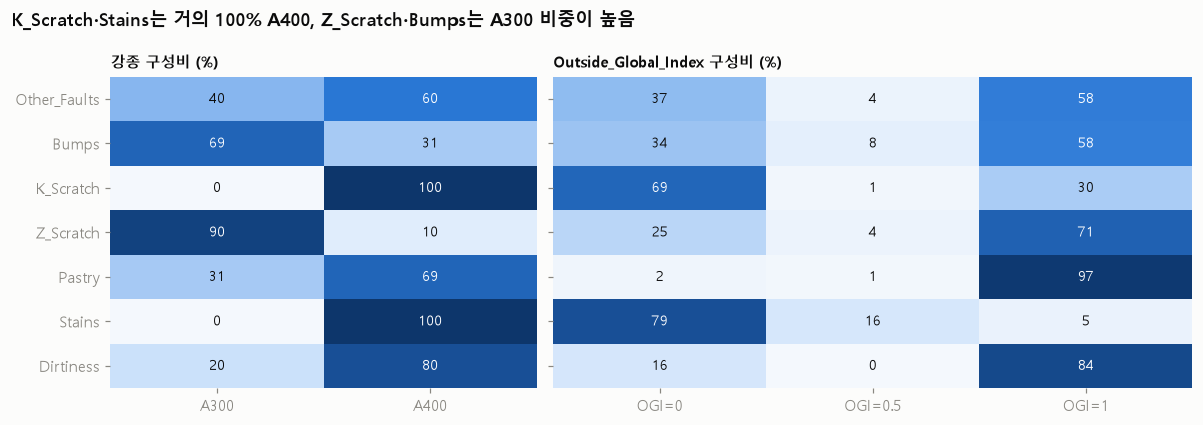

,A300,A400,OGI=0,OGI=0.5,OGI=1
target,,,,,
Other_Faults,39.8,60.2,37.2,4.5,58.4
Bumps,69.2,30.8,34.0,8.1,57.9
K_Scratch,0.0,100.0,68.7,1.3,30.0
Z_Scratch,90.1,9.9,25.0,3.9,71.1
Pastry,31.0,69.0,2.4,0.8,96.8
Stains,0.0,100.0,79.3,15.5,5.2
Dirtiness,20.5,79.5,15.9,0.0,84.1


In [12]:
# 이산형 변수와 클래스의 교차표 (Train, 행=클래스 기준 비율)
steel = pd.crosstab(y_tr, X_tr["TypeOfSteel_A300"].map({1: "A300", 0: "A400"}), normalize="index").reindex(CLASS_ORDER) * 100
ogi = pd.crosstab(y_tr, X_tr["Outside_Global_Index"], normalize="index").reindex(CLASS_ORDER) * 100
ogi.columns = [f"OGI={c:g}" for c in ogi.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw=dict(width_ratios=[2, 3]))
for ax, tab, ttl in [(axes[0], steel, "강종 구성비 (%)"), (axes[1], ogi, "Outside_Global_Index 구성비 (%)")]:
    im = ax.imshow(tab.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(tab.shape[1]), tab.columns); ax.set_yticks(range(7), CLASS_ORDER if ax is axes[0] else [""] * 7)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]; ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 55 else INK)
    ax.grid(False); ax.set_title(ttl, fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("K_Scratch·Stains는 거의 100% A400, Z_Scratch·Bumps는 A300 비중이 높음", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_eda_discrete_vs_class.png")
pd.concat([steel.round(1), ogi.round(1)], axis=1)

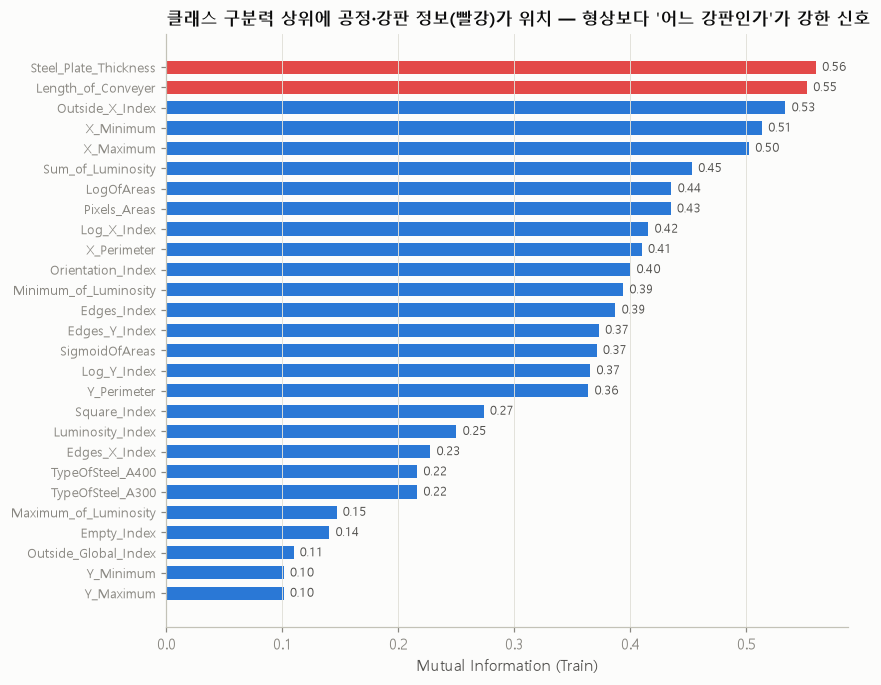

,MI,KW_H,KW_p
Steel_Plate_Thickness,0.5600,510.8917,0.0
Length_of_Conveyer,0.5523,315.6351,0.0
Outside_X_Index,0.5337,647.5910,0.0
X_Minimum,0.5135,493.7609,0.0
X_Maximum,0.5023,324.4412,0.0
Sum_of_Luminosity,0.4531,656.8392,0.0
LogOfAreas,0.4354,625.8363,0.0
Pixels_Areas,0.4348,625.8363,0.0
Log_X_Index,0.4155,637.8982,0.0
X_Perimeter,0.4098,584.7961,0.0


In [13]:
# 변수별 클래스 구분력: Mutual Information(비선형 관계 포함) + Kruskal-Wallis H(클래스 간 분포 차이, 비모수)
disc_mask = [c in DISCRETE_FEATURES + ["TypeOfSteel_A400"] for c in FEATURES_RAW]
mi = mutual_info_classif(X_tr, y_tr, discrete_features=disc_mask, random_state=RANDOM_STATE)
kw = {c: kruskal(*[X_tr.loc[y_tr == k, c] for k in CLASS_ORDER]) for c in FEATURES_RAW}
rel = pd.DataFrame({"MI": mi, "KW_H": [kw[c].statistic for c in FEATURES_RAW],
                    "KW_p": [kw[c].pvalue for c in FEATURES_RAW]}, index=FEATURES_RAW).sort_values("MI", ascending=False)
rel.to_csv(EDA_DIR / "Taegyeom_eda_feature_target_relation.csv")

fig, ax = plt.subplots(figsize=(8, 7))
r = rel["MI"].iloc[::-1]
hi = {"Steel_Plate_Thickness", "Length_of_Conveyer"}
ax.barh(r.index, r.values, color=[RED if c in hi else BLUE for c in r.index], height=0.65)
for i, v in enumerate(r.values): ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("Mutual Information (Train)"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("클래스 구분력 상위에 공정·강판 정보(빨강)가 위치 — 형상보다 '어느 강판인가'가 강한 신호")
save(fig, "Taegyeom_eda_mutual_information.png")
rel.round(4)

**해석 (Train 기준)**
- **크기**: K_Scratch는 면적(LogOfAreas 중앙값 3.8 ≈ 6,300px)이 다른 유형보다 **한 자릿수 이상 큼**, Stains는 가장 작음(≈16px). 크기만으로 두 유형은 상당 부분 구분됩니다.
- **위치**: K_Scratch(X_Minimum 중앙값 41)와 Z_Scratch(121)는 **강판 X축 가장자리 쪽**에 몰려 있고, 나머지는 중앙(600~800)에 분포합니다.
- **강종**: K_Scratch·Stains는 Train에서 **100% A400** (전체 데이터에서도 각 1건만 A300), Z_Scratch(A300 90%)·Bumps(A300 69%)는 A300 비중이 높습니다.
- **방향/형상**: Pastry·Dirtiness는 `Orientation_Index`가 양수(세로로 긴 형상), K_Scratch는 음수(가로로 긴 형상)입니다.
- **Other_Faults**는 거의 모든 변수에서 다른 유형과 범위가 겹치는 **이질적 집합** → 다른 유형과의 혼동이 가장 많을 것으로 예상됩니다.
- **주의할 신호**: MI 상위 1·2위가 `Steel_Plate_Thickness`, `Length_of_Conveyer` 입니다. 이 둘은 결함의 형상이 아니라
  **어느 강판/생산 조건에서 나온 결함인가**를 나타내는 변수입니다(아래 2-7에서 추가 분석).
- 모든 변수의 Kruskal-Wallis 검정 p값이 매우 작아 클래스 간 분포 차이는 통계적으로 유의하지만, 다변량 모델에서의 실제 기여는 최종 모델의 Feature Importance로 확인합니다.

## 2-6. Feature 간 상관관계 (Train 기준)

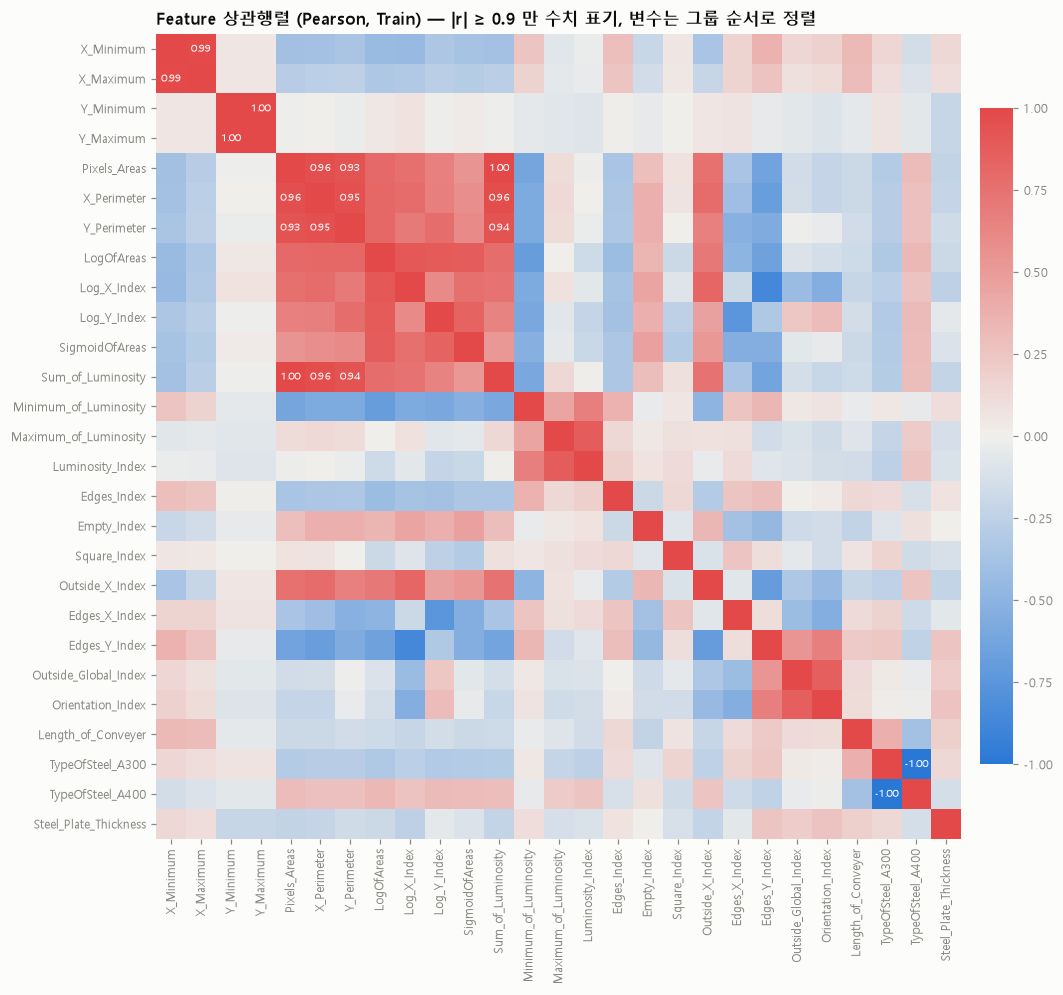

,변수1,변수2,r
19,TypeOfSteel_A300,TypeOfSteel_A400,-1.000
1,Y_Minimum,Y_Maximum,1.000
5,Pixels_Areas,Sum_of_Luminosity,0.997
0,X_Minimum,X_Maximum,0.988
8,X_Perimeter,Sum_of_Luminosity,0.961
2,Pixels_Areas,X_Perimeter,0.960
6,X_Perimeter,Y_Perimeter,0.952
10,Y_Perimeter,Sum_of_Luminosity,0.935
3,Pixels_Areas,Y_Perimeter,0.933
11,LogOfAreas,Log_X_Index,0.891


In [14]:
corr = X_tr.corr()
order = [c for g in groups.values() for c in g]
corr = corr.loc[order, order]
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8); ax.set_yticks(range(len(order)), order, fontsize=8)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j and abs(corr.values[i, j]) >= 0.9:
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white")
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
ax.set_title("Feature 상관행렬 (Pearson, Train) — |r| ≥ 0.9 만 수치 표기, 변수는 그룹 순서로 정렬")
save(fig, "Taegyeom_eda_correlation_heatmap.png")

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(order) for b in order[i + 1:] if abs(corr.loc[a, b]) >= 0.8]
high_corr = pd.DataFrame(pairs, columns=["변수1", "변수2", "r"]).sort_values("r", key=abs, ascending=False).round(3)
high_corr.to_csv(EDA_DIR / "Taegyeom_eda_high_correlation_pairs.csv", index=False)
high_corr

**해석**
- `TypeOfSteel_A300` ↔ `A400` 은 **r = -1.00** (정의상 A400 = 1 − A300) → 하나는 완전 중복입니다(4번 전처리에서 제외).
- `Y_Minimum` ↔ `Y_Maximum` (1.00), `X_Minimum` ↔ `X_Maximum` (0.99): 결함 높이·폭이 강판 크기에 비해 매우 작아 사실상 같은 위치 정보입니다.
- 면적·둘레·밝기합(`Pixels_Areas`, `X/Y_Perimeter`, `Sum_of_Luminosity`)은 서로 0.9 이상 → 모두 "결함 크기"를 다른 방식으로 측정한 값입니다.
- Tree 계열은 상관 변수에 비교적 강하지만, **로지스틱 회귀는 다중공선성으로 계수가 불안정**할 수 있습니다.
  전처리에서는 정의상 완전 중복인 A400만 제외하고, 나머지 고상관 변수의 **유지/제외 효과는 이후 실험으로 비교**합니다.

## 2-7. 추가 탐색: 같은 강판(생산 조건) 효과
데이터에는 강판 ID가 없지만, `Length_of_Conveyer` × `Steel_Plate_Thickness` × 강종 조합은 **같은 강판/생산 배치의 대리 변수**로 볼 수 있습니다.

In [15]:
plate = raw[["Length_of_Conveyer", "Steel_Plate_Thickness", "TypeOfSteel_A300"]].astype(str).agg("_".join, axis=1)
ct = pd.crosstab(plate, y_all)
purity = ct.max(axis=1).sum() / len(raw)
in_train = plate.loc[test_idx].isin(set(plate.loc[train_idx])).mean()
size = plate.value_counts()
print(f"조합(강판 대리 그룹) 수: {plate.nunique()}개, 그룹당 결함 수 중앙값 {size.median():.0f} / 최대 {size.max()}")
print(f"그룹 내 최빈 클래스 비율(가중 순도): {purity:.1%}  → 그룹만 알아도 약 {purity:.0%}를 맞힐 수 있음")
print(f"Test 행 중 같은 그룹이 Train에 존재하는 비율: {in_train:.1%}")

조합(강판 대리 그룹) 수: 239개, 그룹당 결함 수 중앙값 3 / 최대 133
그룹 내 최빈 클래스 비율(가중 순도): 76.6%  → 그룹만 알아도 약 77%를 맞힐 수 있음
Test 행 중 같은 그룹이 Train에 존재하는 비율: 93.8%


**해석과 시사점**
- 239개 그룹 안에서 **한 유형이 차지하는 비율이 평균 76.6%** 로, 같은 강판/생산 조건에서는 같은 유형의 결함이 반복되는 경향이 강합니다.
- Test 결함의 **93.8%는 같은 그룹의 결함이 Train에도 존재**합니다. 따라서 랜덤 층화 분할의 성능은
  "이미 본 강판에서 나온 다른 결함"을 맞히는 성능에 가깝고, **처음 보는 강판/생산 조건에 대한 일반화 성능보다 낙관적일 수 있습니다.**
- 이 변수들은 실제 검사 시점에도 알 수 있는 정보이므로 **Target 누수는 아니며** 입력에서 제외하지 않습니다.
  대신 **한계로 기록**하고, 심화 단계에서 그룹 단위 분할(`StratifiedGroupKFold`) 평가로 일반화 가능성을 별도 확인할 계획입니다.

---
# 3. 평가 기준 설정

### 3-1. 핵심 지표: **Macro F1-score**
| 고려 사항 | 근거 |
|---|---|
| 문제의 핵심 오류 | 1번 문제 정의에서 정한 대로 **소수 유형을 다수 유형으로 흡수해 놓치는 오류**가 가장 중요 |
| Accuracy의 한계 | 다수 3개 클래스가 75.5% → 소수 유형을 모두 틀려도 Accuracy는 높게 유지될 수 있음 |
| Recall만 볼 때의 한계 | 소수 클래스를 과다 예측하면 Recall은 오르지만 오경보(Precision 저하)로 불필요한 공정 점검 비용 발생 |
| **Macro F1 선택 이유** | 클래스별 F1(Precision·Recall 조화평균)을 **건수와 무관하게 동일 가중 평균** → Dirtiness(55건)의 성능이 Other_Faults(673건)와 같은 비중으로 반영 |
| 목표 | **최종 모델 Macro F1 ≥ 0.83** (튜터 가이드, 기준 모델 약 0.82) |

### 3-2. 보조 지표
| 지표 | 용도 |
|---|---|
| **클래스별 Precision / Recall / F1** | 어떤 유형이 개선·악화되었는지 확인. 특히 **Dirtiness·Stains·Pastry의 Recall**과 그 대가로 발생한 Precision 변화 |
| **Confusion Matrix** | 어떤 유형이 어떤 유형으로 오분류되는지 확인 (아래 3-3의 주요 오분류 유형 추적) |
| Weighted F1 | 실제 분포(건수 가중) 기준 전반적 성능 — Macro F1과의 차이로 다수/소수 클래스 성능 격차 파악 |
| Accuracy | 전체 정확도. 불균형 처리 후 **얼마나 감소했는지** Trade-off 확인용 |
| Macro ROC-AUC (OvR) | 임계값과 무관한 순위 분리 능력. 확률 기반 모델 비교·도전 실습 A(Threshold) 참고용 |

### 3-3. Confusion Matrix에서 중점적으로 볼 오분류
1. **Dirtiness / Stains / Pastry → Other_Faults·Bumps** (소수 유형 놓침) — 건수와 비율 모두 추적
2. **Other_Faults → 소수 유형** (불균형 처리 후 증가하기 쉬운 오경보)
3. **Bumps ↔ Other_Faults** (다수 클래스 간 혼동, 절대 건수가 가장 클 것으로 예상)
4. **K_Scratch ↔ Z_Scratch** (긁힘 유형 간 혼동)

### 3-4. 평가 절차
- 모델 비교·불균형 처리·튜닝은 **Train 내부 StratifiedKFold 5-fold** 의 평균 ± 표준편차로 판단합니다.
- **Test(389건)는 최종 모델 선정 후 1회만** 평가합니다. 희소 클래스는 Test 건수가 11~14건이므로 클래스별 지표에 **Test 표본 수를 함께 표기**합니다.

In [16]:
# 팀 config.SCORING에 보조 지표(Macro Precision/Recall, Macro ROC-AUC)를 더한 평가 지표 (Taegyeom_model_utils)
SCORING_EXTENDED

{'macro_f1': 'f1_macro',
 'weighted_f1': 'f1_weighted',
 'accuracy': 'accuracy',
 'macro_precision': 'precision_macro',
 'macro_recall': 'recall_macro',
 'macro_roc_auc_ovr': 'roc_auc_ovr'}

---
# 4. 데이터 품질 확인 및 전처리
## 4-1. 품질 점검 (자동 검증)
`src/Taegyeom_model_utils.py`의 `validate_raw()` 로 구조·품질·도메인 논리를 검증합니다. 하나라도 실패하면 예외가 발생합니다.

In [17]:
validate_raw(raw)

X_all = raw[FEATURES_RAW]
checks = pd.DataFrame([
    ["결측치", "전체 셀 결측 수", int(raw.isna().sum().sum())],
    ["중복", "전체 행 중복", int(raw.duplicated().sum())],
    ["중복", "입력값(27개) 기준 중복", int(X_all.duplicated().sum())],
    ["Target", "정답 열 0/1 이외 값", int((~raw[TARGET_COLS].isin([0, 1])).sum().sum())],
    ["Target", "정답 행 합 ≠ 1", int((raw[TARGET_COLS].sum(axis=1) != 1).sum())],
    ["논리", "X_Minimum > X_Maximum", int((raw.X_Minimum > raw.X_Maximum).sum())],
    ["논리", "Y_Minimum > Y_Maximum", int((raw.Y_Minimum > raw.Y_Maximum).sum())],
    ["논리", "최소 밝기 > 최대 밝기", int((raw.Minimum_of_Luminosity > raw.Maximum_of_Luminosity).sum())],
    ["논리", "X_Maximum > Length_of_Conveyer", int((raw.X_Maximum > raw.Length_of_Conveyer).sum())],
    ["논리", "Pixels_Areas ≤ 0", int((raw.Pixels_Areas <= 0).sum())],
    ["범주", "A300 + A400 ≠ 1", int((raw.TypeOfSteel_A300 + raw.TypeOfSteel_A400 != 1).sum())],
], columns=["구분", "점검 항목", "해당 건수"])
checks.to_csv(EDA_DIR / "Taegyeom_eda_quality_checks.csv", index=False)
checks

,구분,점검 항목,해당 건수
0,결측치,전체 셀 결측 수,0
1,중복,전체 행 중복,0
2,중복,입력값(27개) 기준 중복,0
3,Target,정답 열 0/1 이외 값,0
4,Target,정답 행 합 ≠ 1,0
5,논리,X_Minimum > X_Maximum,0
6,논리,Y_Minimum > Y_Maximum,0
7,논리,최소 밝기 > 최대 밝기,0
8,논리,X_Maximum > Length_of_Conveyer,0
9,논리,Pixels_Areas ≤ 0,0


## 4-2. 이상치 확인 (IQR 1.5배 기준, Train)

In [18]:
out = desc[["min", "50%", "max", "skew", "IQR 이상치 비율(%)"]].sort_values("IQR 이상치 비율(%)", ascending=False).head(10)
# 이상치가 특정 클래스에 몰려 있는지 확인
def iqr_flag(s): q1, q3 = s.quantile([.25, .75]); return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))
by_cls = pd.DataFrame({c: y_tr[iqr_flag(X_tr[c])].value_counts(normalize=True).reindex(CLASS_ORDER).fillna(0) * 100
                       for c in ["Pixels_Areas", "Sum_of_Luminosity", "Outside_X_Index", "X_Perimeter", "Steel_Plate_Thickness"]}).T.round(1)
by_cls.columns.name = "이상치 행의 클래스 구성(%)"
display(out); by_cls

,min,50%,max,skew,IQR 이상치 비율(%)
Sum_of_Luminosity,250.000,19125.000,3.918209e+06,3.246,20.490
Pixels_Areas,2.000,170.500,3.733400e+04,3.107,20.425
Outside_X_Index,0.002,0.010,8.760000e-01,5.256,19.265
X_Perimeter,2.000,26.500,1.275000e+03,2.848,18.363
Steel_Plate_Thickness,40.000,69.000,3.000000e+02,2.219,12.307
Y_Perimeter,1.000,25.000,9.030000e+02,2.806,9.665
Maximum_of_Luminosity,37.000,127.000,2.530000e+02,1.223,7.925
Luminosity_Index,-0.999,-0.133,6.420000e-01,0.599,7.410
Y_Minimum,6712.000,1188619.000,1.298766e+07,2.810,4.510
Y_Maximum,6724.000,1188705.500,1.298769e+07,2.810,4.510


이상치 행의 클래스 구성(%),Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness
Pixels_Areas,10.1,1.3,82.6,2.8,2.8,0.0,0.3
Sum_of_Luminosity,10.1,1.3,83.0,2.8,2.8,0.0,0.0
Outside_X_Index,10.0,1.7,87.3,1.0,0.0,0.0,0.0
X_Perimeter,11.2,1.8,82.1,3.2,1.8,0.0,0.0
Steel_Plate_Thickness,70.7,12.0,0.0,4.7,12.0,0.0,0.5


**판단: 이상치는 제거·클리핑하지 않고 유지합니다.**
- 크기·밝기 변수 이상치(약 20%)의 **대부분이 K_Scratch** 입니다. 즉 이상치는 측정 오류가 아니라 **"대형 긁힘"이라는 유형 고유의 특성**이며,
  제거하면 K_Scratch를 구분하는 핵심 정보를 잃습니다.
- 도메인 논리 검증(최소 ≤ 최대, 위치 ≤ 컨베이어 길이 등)을 모두 통과해 **명백한 오류값은 없습니다.**
- 대신 로지스틱 회귀에는 **StandardScaler**를 적용하고, 왜도가 큰 변수의 **log1p 변환은 "전처리 변경 실험"** 으로 효과를 따로 비교합니다
  (`build_preprocessor(..., log_skewed=True)`). Tree 계열은 단조 변환·이상치에 영향이 작아 원본을 사용합니다.

## 4-3. 파생 지표와 중복 정보 확인

In [19]:
w = raw.X_Maximum - raw.X_Minimum; h = raw.Y_Maximum - raw.Y_Minimum
deriv = pd.DataFrame([
    ["LogOfAreas", "log10(Pixels_Areas)", float(np.abs(raw.LogOfAreas - np.log10(raw.Pixels_Areas)).max())],
    ["Log_X_Index", "log10(X_Maximum − X_Minimum)", float(np.abs(raw.Log_X_Index - np.log10(w.clip(lower=1))).max())],
    ["Log_Y_Index", "log10(Y_Maximum − Y_Minimum)", float(np.abs(raw.Log_Y_Index - np.log10(h.clip(lower=1))).max())],
    ["TypeOfSteel_A400", "1 − TypeOfSteel_A300", float(np.abs(raw.TypeOfSteel_A400 - (1 - raw.TypeOfSteel_A300)).max())],
], columns=["변수", "재현 수식", "최대 절대오차"])
deriv

,변수,재현 수식,최대 절대오차
0,LogOfAreas,log10(Pixels_Areas),0.000055
1,Log_X_Index,log10(X_Maximum − X_Minimum),0.000054
2,Log_Y_Index,log10(Y_Maximum − Y_Minimum),0.000054
3,TypeOfSteel_A400,1 − TypeOfSteel_A300,0.000000


- `LogOfAreas`, `Log_X_Index`, `Log_Y_Index`는 원본 변수로 **소수점 반올림 오차 수준까지 재현**되는 파생 지표입니다.
  정보는 중복되지만 log 스케일 표현이 로지스틱 회귀에 유리할 수 있어 **Baseline에서는 유지**하고, 제외 효과는 이후 실험으로 비교합니다.
- `TypeOfSteel_A400`은 **정의상 1 − A300**이므로 데이터 통계에 의존하지 않는 규칙으로 **제외**합니다(누수 없음).
  로지스틱 회귀에서 절편과 완전 공선성을 만들고 정보 이득은 0이기 때문입니다.

## 4-4. 점검 결과 요약 및 처리 방법
| 점검 항목 | 확인 결과 | 처리 | 이유 |
|---|---|---|---|
| **결측치** | 0건 | 대체 불필요. 단 Pipeline에 `SimpleImputer(median / most_frequent)` 유지 | 신규 데이터 결측 대비. Training fold 기준 fit이라 누수 없음 |
| **중복** | 전체 행 0건, 입력값 기준 0건 | 처리 불필요 | — |
| **이상치** | 크기·밝기 변수 IQR 이상치 약 20%, 대부분 K_Scratch | **유지** (제거·클리핑 안 함) | 유형 고유 특성. 도메인 논리 검증 통과 |
| **분포 왜곡** | Pixels_Areas 등 왜도 2.8~5.3 (Train), 극단값 1건은 Test에 존재 | LR: StandardScaler / log1p는 실험 옵션, Tree: 미적용 | 팀 기준(필요한 모델만 Scaling) |
| **범주형** | 문자열 범주 없음. 강종 0/1, Outside_Global_Index 0/0.5/1 | **원핫 인코딩 불필요**, A400 제외, 이산 변수는 Scaling 제외 | 이미 숫자 표시형. SMOTENC 시 범주 지정 대상 |
| **식별자** | ID 열 없음. 파일이 클래스 순 정렬 | 제외할 열 없음. **shuffle 포함 층화 분할/CV 필수** | 순서 자체가 정보가 되지 않도록 |
| **데이터 누수** | 정답 열 7개 | **X에서 7개 모두 제외** → 단일 `target` | 정답 그 자체 |
| 〃 | 강판 대리 그룹(두께·컨베이어·강종) | 유지 + **한계로 기록**, 심화에서 그룹 분할 평가 | 검사 시점에 알 수 있는 정보(누수 아님)이나 낙관적 평가 가능 |
| **고상관 변수** | Y_Min/Max 1.00, 면적·밝기합 0.997, X_Min/Max 0.99, 면적·둘레 0.96 등 (Train) | Baseline 유지, 유지/제외 실험 | 모델별 영향이 다를 수 있어 실험으로 판단 |

## 4-5. 분석 대상 데이터 확인 (`Faults_processed.csv`)
행 단위 변환만 수행하므로 Train/Test 분리 전에 적용해도 누수가 없습니다. **원본 행 순서와 index를 유지**하여 `data/split/*_idx.csv`와 정합됩니다.
`data/processed/Faults_processed.csv`는 팀 공통 전처리(`02_preprocessing.ipynb`)로 이미 만들어져 있으므로, 여기서는 **같은 규칙으로 다시 만든 결과가 팀 파일과 완전히 같은지 검증**하고 파일은 덮어쓰지 않습니다.

In [20]:
processed = make_processed(raw)
PROCESSED_PATH = BASE_DIR / "data" / "processed" / "Faults_processed.csv"
if PROCESSED_PATH.exists():
    team = pd.read_csv(PROCESSED_PATH)
    assert processed.equals(team), "팀 공통 Faults_processed.csv와 다름"
    print("팀 공통 Faults_processed.csv와 완전히 동일함을 확인했습니다 (행·열·값·순서).")
else:
    processed.to_csv(PROCESSED_PATH, index=False); print("Faults_processed.csv를 새로 저장했습니다.")

assert (processed.index == raw.index).all() and (processed[TARGET_NAME] == y_all).all()
summary = pd.DataFrame({
    "구분": ["원본", "분석 대상"],
    "행 수": [raw.shape[0], processed.shape[0]],
    "열 수": [raw.shape[1], processed.shape[1]],
    "입력 변수 수": [len(FEATURES_RAW), processed.shape[1] - 1],
    "제외 기준": ["—", "정답 표시 열 7개(누수) + TypeOfSteel_A400(정의상 중복)"],
})
summary

팀 공통 Faults_processed.csv와 완전히 동일함을 확인했습니다 (행·열·값·순서).


,구분,행 수,열 수,입력 변수 수,제외 기준
0,원본,1941,34,27,—
1,분석 대상,1941,27,26,정답 표시 열 7개(누수) + TypeOfSteel_A400(정의상 중복)


## 4-6. Train/Test 분리 및 학습 데이터 기준 전처리
- 분할: 팀 공통 `src/make_split.py` (80:20, Stratified, `random_state=42`) → `load_data()`로 동일 index 사용
- **데이터로부터 학습하는 전처리(결측 대체, Scaling)는 `build_preprocessor()` 로 정의하여 모델 Pipeline 안에 넣습니다.**
  `cross_validate` 시 각 Training fold에서만 fit 되고 Validation fold에는 transform만 적용됩니다.
- 클래스 불균형 처리의 Sampling도 `imblearn.pipeline.Pipeline` 내부에 두어 Training fold에만 적용합니다.

In [22]:
from load_data import load_data
X_train, X_test, y_train, y_test = load_data()
print("X_train", X_train.shape, "| X_test", X_test.shape)
print("입력 변수:", list(X_train.columns))

pre_tree = build_preprocessor(list(X_train.columns), scale=False)             # Tree 계열
pre_lr   = build_preprocessor(list(X_train.columns), scale=True)              # Logistic Regression
pre_lr_log = build_preprocessor(list(X_train.columns), scale=True, log_skewed=True)  # 전처리 변경 실험용

X_train (1552, 26) | X_test (389, 26)
입력 변수: ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']


In [23]:
# 누수 방지 확인: Scaler는 Train으로만 fit → Train 평균 0 / 표준편차 1, Test는 Train 기준으로 변환되어 정확히 0/1이 아님
pre_lr.fit(X_train)
Ztr, Zte = pre_lr.transform(X_train), pre_lr.transform(X_test)
n_cont = Ztr.shape[1] - len(DISCRETE_FEATURES)
print("Train 연속형 평균 |max|:", np.abs(Ztr[:, :n_cont].mean(0)).max().round(4), " 표준편차 범위:", Ztr[:, :n_cont].std(0).min().round(3), "~", Ztr[:, :n_cont].std(0).max().round(3))
print("Test  연속형 평균 |max|:", np.abs(Zte[:, :n_cont].mean(0)).max().round(4), " (Train 통계로 변환되었기 때문에 0이 아님)")
print("이산형 변수는 Scaling 제외:", list(pre_lr.get_feature_names_out()[-len(DISCRETE_FEATURES):]))

Train 연속형 평균 |max|: 0.0  표준편차 범위: 1.0 ~ 1.0
Test  연속형 평균 |max|: 0.3529  (Train 통계로 변환되었기 때문에 0이 아님)
이산형 변수는 Scaling 제외: ['TypeOfSteel_A300', 'Outside_Global_Index']


---
# 요약 및 모델링으로 넘기는 결정 사항
| 항목 | 결정 |
|---|---|
| 문제 | 7-class 다중 분류, 검사자 유형 판정 보조. **소수 유형 놓침(Recall)** 을 중시하되 오경보와 균형 |
| 핵심 지표 | **Macro F1** (목표 ≥ 0.83), 보조: 클래스별 P/R/F1, Confusion Matrix, Weighted F1, Accuracy, Macro ROC-AUC |
| 분석 대상 | 1,941행 × 입력 26개 + `target` (정답 7개·A400 제외) |
| 분할 | Train 1,552 / Test 389, 층화, `random_state=42`. CV는 Train 내부 StratifiedKFold 5-fold |
| 전처리 | Tree: imputer만 / LR: imputer + StandardScaler(이산형 제외). 이상치·고상관 변수 유지 |
| 이후 실험 후보 | LR log1p 변환, 고상관 변수 제외, Class Weight / RUS / SMOTENC(`DISCRETE_FEATURES` 지정) |
| 기록할 한계 | 희소 클래스 Test 11~14건(1건=7~9%p), 강판 대리 그룹 공유 93.8%로 랜덤 분할 성능이 낙관적일 가능성 |